# 4. Employee Salary Analysis (Box Plot + Histogram)
Analyze the distribution of employee salaries across departments using box plots and a histogram. Columns: Department, Salary Requirements:

- Create side-by-side box plots for each department.
- Use a histogram to visualize overall salary distribution.
- Detect outliers and describe their potential causes.
- Add the median, mean, and interquartile range (IQR) annotations.

In [7]:
import pandas as pd
import matplotlib.pyplot as plt

department = pd.read_csv(
    "seh.csv", 
    names=['id', 'name', 'shift', 'hasPlan', 'filial_id', 'emergency', 'salaryDay'],
    usecols=['id', 'name']
)

salary = pd.read_csv(
    "salary.csv", 
    names=['id', 'user_id', 'year', 'month', 'salary', 'daily', 'tax', 'additional_wage', 'calculated_wage', 'avans', 'taken_money', 'workdays', 'workingDayCount', 'seh_id'],
    usecols=['user_id', 'year', 'month', 'salary', 'calculated_wage', 'seh_id']
)

# Merge the two datasets
data = pd.merge(salary, department, left_on='seh_id', right_on='id')

# Group and aggregate
report_summary = (
    data.groupby(['name', 'year', 'month'], as_index=False)['calculated_wage']
    .sum()
).sort_values(['year', 'month'])

# Pivot properly and reassign
report_pivot = report_summary.pivot(
    index="name",
    columns=['year', 'month'],
    values="calculated_wage"
)

# Flatten the MultiIndex columns (year, month) into "YYYY-MM" strings
report_pivot.columns = [f"{y}-{m:02d}" for (y, m) in report_pivot.columns]

# Fill NaNs with zeros
report_pivot = report_pivot.fillna(0)

print(report_pivot.head())


                  2023-03     2023-06     2023-07   2023-08   2023-09  \
name                                                                    
Ё                     0.0         0.0         0.0       0.0       0.0   
Ёрдамчи ходимлар      0.0         0.0         0.0       0.0       0.0   
БЕТОН                 0.0         0.0         0.0       0.0       0.0   
Бошкарув              0.0  23246676.0         0.0  112903.0  133333.0   
Брусчатка цехи        0.0   7823393.0  12180380.0       0.0       0.0   

                  2023-11     2023-12     2024-01     2024-02     2024-03  \
name                                                                        
Ё                     0.0         0.0         0.0         0.0         0.0   
Ёрдамчи ходимлар      0.0         0.0         0.0         0.0         0.0   
БЕТОН                 0.0         0.0         0.0   1551720.0         0.0   
Бошкарув              0.0  12322580.0  72285383.0  78044987.0  85813224.0   
Брусчатка цехи        0.0 

Department 'Ё' outliers: [1.354836]
Department 'Брусчатка цехи' outliers: [12.18038  26.233035 43.576092 36.702897 53.424686]
Department 'Лоток плита цех' outliers: [ 7.6      39.359997 29.167327 26.811249 40.639996 33.835    33.654998]
Department 'Обём ходимлар' outliers: [106.188092  77.391231]


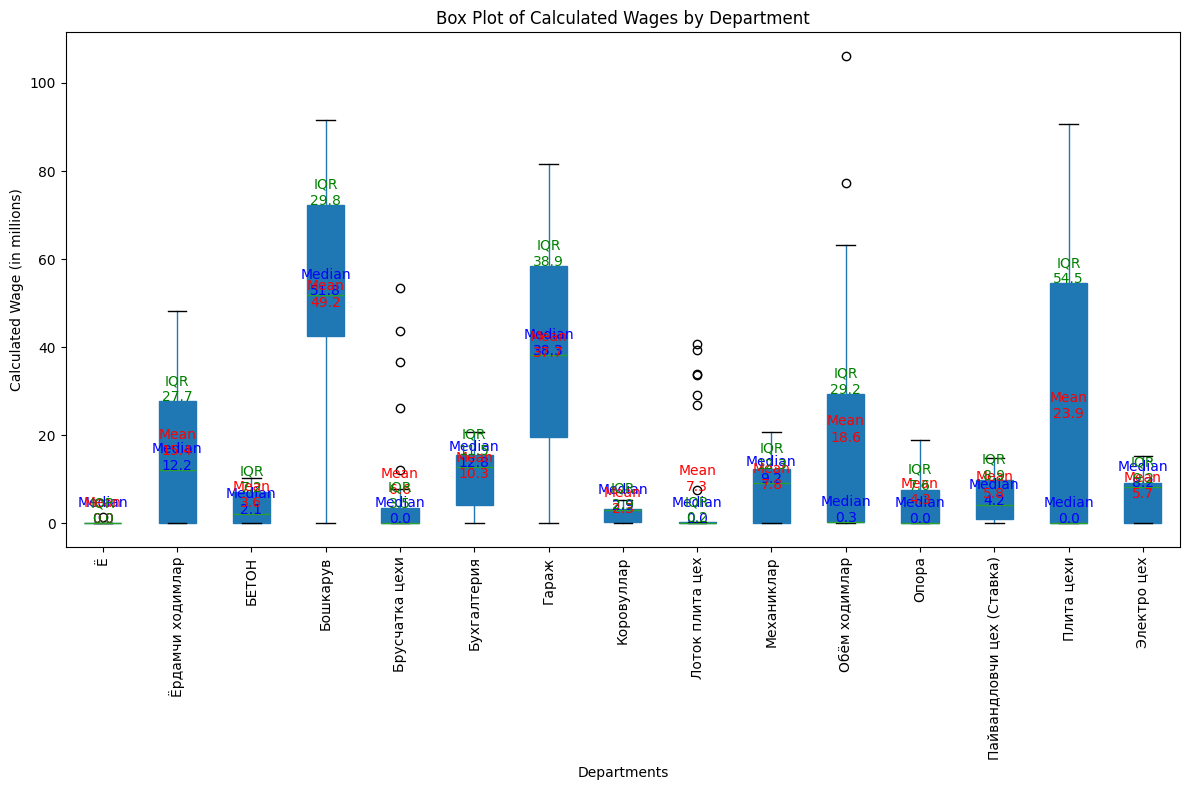

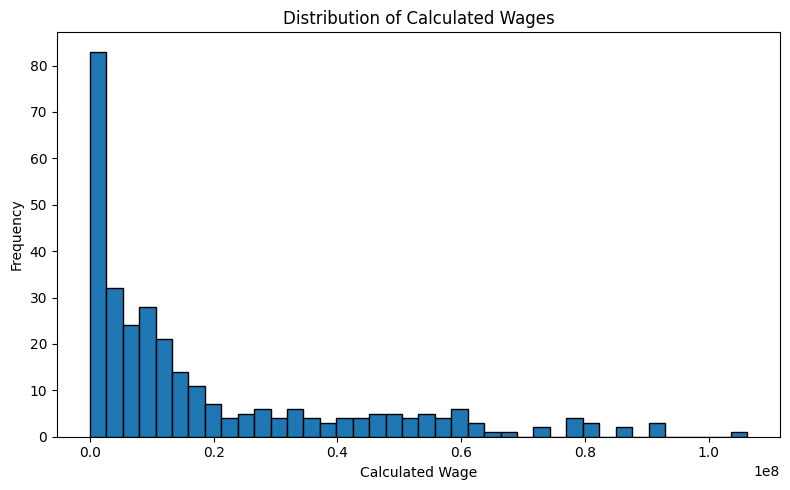


------------------------------------------
✅ Runtime: 202.1 ms | 💾 Mem: 167.38 MB (Δ +8.06 MB) | ⚙️ CPU: 11.4%


In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Flatten pivot for plotting statistics
wages = report_summary['calculated_wage']

# --- BOX PLOT with median, mean, IQR, and outlier detection ---
plt.figure(figsize=(12, 8))

box = (report_pivot / 1_000_000).T.boxplot(grid=False, patch_artist=True)

# Calculate statistics for annotations
for i, department in enumerate(report_pivot.index):
    dept_data = report_pivot.loc[department].values / 1_000_000
    median = np.median(dept_data)
    mean = np.mean(dept_data)
    q1 = np.percentile(dept_data, 25)
    q3 = np.percentile(dept_data, 75)
    iqr = q3 - q1
    
    # Annotate median
    plt.text(i + 1, median, f'Median\n{median:.1f}', horizontalalignment='center', color='blue')
    # Annotate mean
    plt.text(i + 1, mean, f'Mean\n{mean:.1f}', horizontalalignment='center', color='red')
    # Annotate IQR
    plt.text(i + 1, q3, f'IQR\n{iqr:.1f}', horizontalalignment='center', color='green')
    
    # Detect outliers
    outliers = dept_data[(dept_data < q1 - 1.5*iqr) | (dept_data > q3 + 1.5*iqr)]
    if len(outliers) > 0:
        print(f"Department '{department}' outliers: {outliers}")

plt.title('Box Plot of Calculated Wages by Department')
plt.xlabel('Departments')
plt.ylabel('Calculated Wage (in millions)')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()


# --- HISTOGRAM ---
plt.figure(figsize=(8, 5))
plt.hist(wages, bins=40, edgecolor='black')
plt.title('Distribution of Calculated Wages')
plt.xlabel('Calculated Wage')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()
